# FLAC 文件夹批量分析

逐个分析指定文件夹及其子文件夹中的 `.flac` 文件，在 Notebook 输出详细报告，并把主要指标写入 CSV。结论只用于筛查，不能单凭频谱证明音源来源。


In [1]:
from pathlib import Path
from flac_forensics import analyze_folder, print_report, plot_spectrum, plot_spectrogram
import matplotlib.pyplot as plt


## 1. 设置文件夹与 CSV 路径

`FOLDER` 可以是绝对路径；`Path(".")` 表示 Notebook 当前工作目录。


In [2]:
FOLDER = Path(".")
CSV_PATH = FOLDER / "flac_analysis.csv"
print("分析目录:", FOLDER.resolve())
print("汇总文件:", CSV_PATH.resolve())


分析目录: F:\Downloads\flac_forensics_tool
汇总文件: F:\Downloads\flac_forensics_tool\flac_analysis.csv


## 2. 批量分析

每个文件都会输出详细报告。无法解码的文件会记录在 CSV 的 `error` 列，不会中断其余文件。


In [3]:
results, errors = analyze_folder(FOLDER, CSV_PATH)
for result in results:
    print_report(result)
for path, message in errors:
    print(f"FAILED: {path}: {message}")
print(f"完成：{len(results)} 个成功，{len(errors)} 个失败。CSV：{CSV_PATH.resolve()}")


FLAC / PCM forensic heuristic report
File:        F:\Downloads\flac_forensics_tool\01. Fragments - Fragments.flac
Format:      FLAC / PCM_16
Audio:       44100 Hz / 2 ch / 16-bit
Duration:    312.774 s
Avg bitrate: 898.6 kbps

Verdict:     存在可疑特征，但不能单凭频谱定性
Confidence:  中等

Spectrum:
  Nyquist:           22.050 kHz
  Spectral edge 95%: 2.042 kHz
  Spectral edge 99%: 8.019 kHz
  Cutoff estimate:   16.594 kHz
  Cutoff confidence: 0.66
  HF correlation:    0.995
  Band energies:
              0-8k:   -49.12 dB
             8-12k:   -67.29 dB
            12-16k:   -72.25 dB
            16-18k:   -83.31 dB
            18-20k:  -100.24 dB
            20-22k:  -100.33 dB
       22k-Nyquist:   -99.56 dB

Bit depth:
  Declared:           16
  Zero-padded likely: False

Rationale:
  - Detected a sustained upper-band cutoff around 16.59 kHz.
  - Top-band activity tracks musical HF content (correlation 1.00), which argues against a completely empty padded high-frequency region.
  - 注意：频谱低通、母带滤波、老录音

## 3. 可选：查看其中一个文件的图

修改 `PLOT_FILE` 为文件夹内的目标 FLAC；默认显示第一个成功分析的文件。


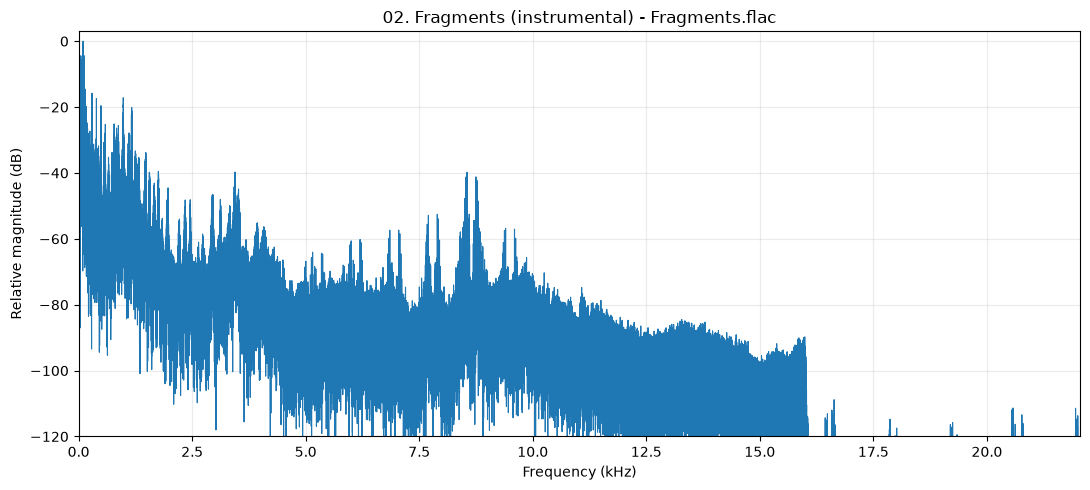

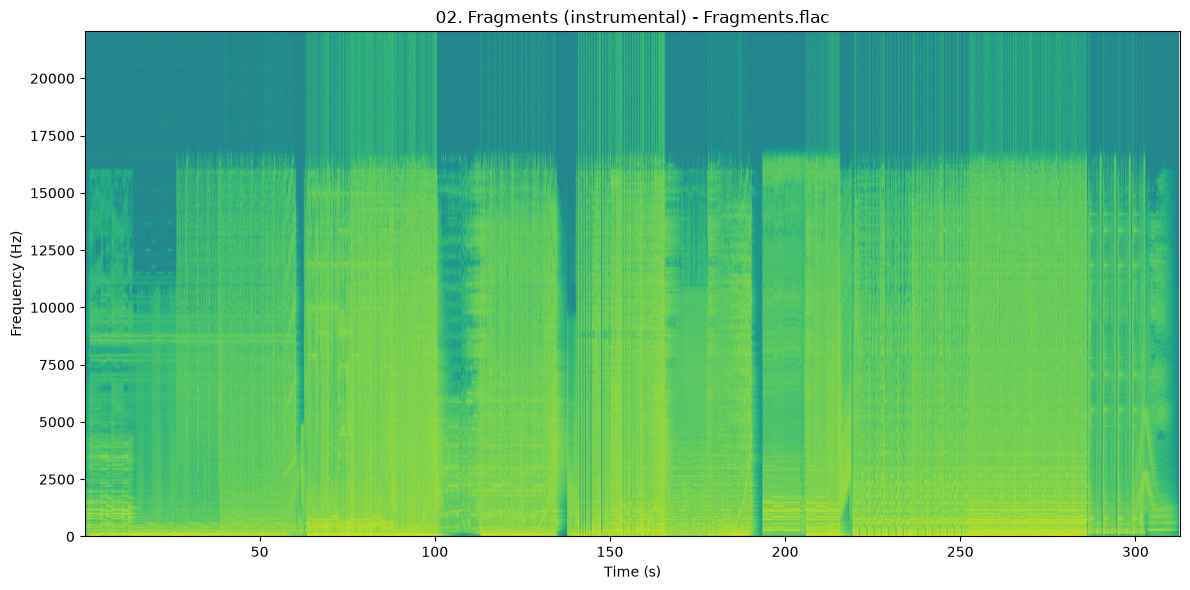

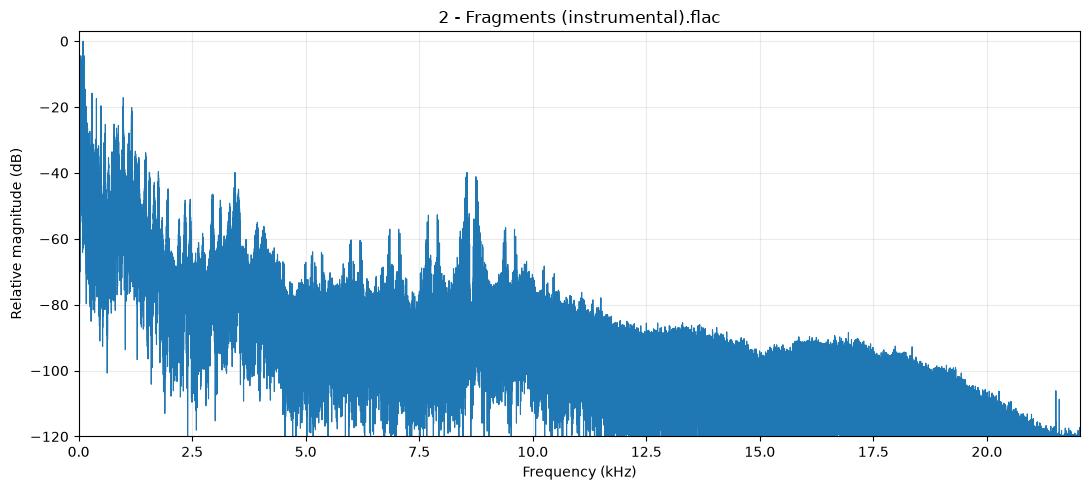

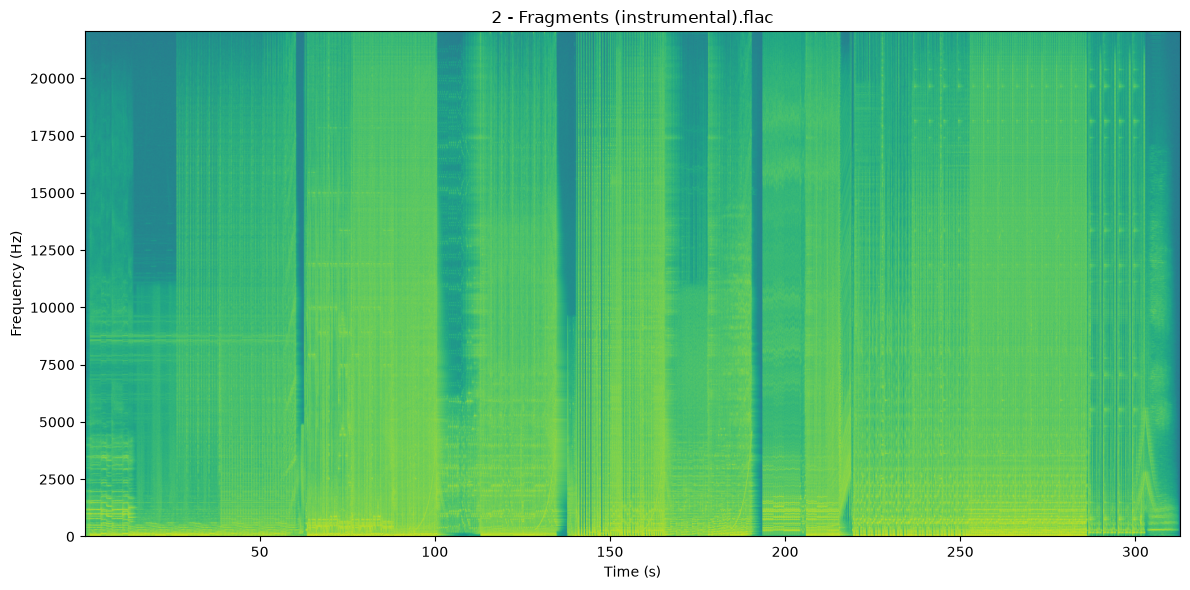

In [18]:
PLOT_FILE = Path(results[1].info.path) if results else None
if PLOT_FILE is not None:
    plot_spectrum(PLOT_FILE)
    plot_spectrogram(PLOT_FILE)
    plt.show()
PLOT_FILE = Path(results[3].info.path) if results else None
if PLOT_FILE is not None:
    plot_spectrum(PLOT_FILE)
    plot_spectrogram(PLOT_FILE)
    plt.show()